# 00 · Kurulum, Veri Kümeleri ve Tekrarlanabilirlik

**Proje:** Genetik Programlama (GP) Destekli Tabakalı SFT Veri Seçimi ve Çift Ölçekli (Proxy → Target) Deneysel Hizalama Mimarisi

**Bu defterin amacı.** Deneylerin geri kalanında kullanılacak (i) yazılım/donanım ortamını belgelemek, (ii) üç veri kümesini
ve bölünmeleri tanımlayıp doğrulamak, (iii) gösterimi sabitlemektir. Böylece sonraki dört defterdeki bulgular tek bir
referans çerçevesine dayanır ve bağımsız bir okuyucu tarafından yeniden üretilebilir.

| Defter | İçerik | Başlıca çıktı |
|---|---|---|
| `00_setup_and_data` | Ortam, veri, bölünmeler | Tablo 1–4, Şekil 1 |
| `01_features_and_clustering` | K-Means (M = 20) + 6 öznitelik | öznitelik matrisi $X \in [0,1]^{N\times 6}$ |
| `02_gp_evolution` | DEAP GP + vekil (0.5B) uygunluk | $f_{GP}^*$, 4 alt küme |
| `03_target_sft_and_alignment` | 3B üzerinde 5 SFT + GRPO / DPO / R-DPO | 11 adaptör, kayıp ve maliyet eğrileri |
| `04_evaluation_and_judge` | Metrikler, $D_{KL}$, gpt-4o hakem | LC kazanma matrisi + %95 GA |

## 0.1 Ortam

In [1]:
# Yalnızca ilk çalıştırmada (Colab): bağımlılıkları kurun. Yerelde requirements.txt kullanın.
# %pip install -q "transformers>=4.50" "trl>=0.20" "peft>=0.14" "bitsandbytes>=0.45" accelerate datasets \
#     sentence-transformers scikit-learn deap pandas pyarrow matplotlib openai sympy scipy joblib tqdm

In [2]:
# --- Ortam kurulumu (Colab + yerel) ---------------------------------------------------
import os, sys, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Colab uzantısında çekirdek uzak makinede çalışır; yerel src/ orada olmadığından depo klonlanır.
if "google.colab" in sys.modules:
    PROJECT = Path("/content/gp-stratified-sft-selection")
    if not PROJECT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/suleymangzy/gp-stratified-sft-selection.git", str(PROJECT)], check=True)
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["PROJECT_ROOT"] = str(PROJECT)                  # çıktılar PROJECT/outputs altına yazılır
sys.path.insert(0, str(PROJECT / "src"))

%matplotlib inline
import numpy as np, pandas as pd
from IPython.display import display, Markdown
from analysis import set_academic_style, show_figure, show_table
set_academic_style()
print("Proje dizini:", PROJECT)

Proje dizini: /content/gp-stratified-sft-selection


### Tekrarlanabilirlik bildirimi
Tüm rastgelelik kaynakları (`random`, `numpy`, `torch`, K-Means, bölünmeler, GP) tek bir tohuma bağlıdır
(`SEED = 42`, [common.py](../src/common.py)). GPU çekirdeklerinin deterministik olmaması ve 4-bit nicemleme nedeniyle
bit düzeyinde özdeşlik **garanti edilmez**; ancak sürüm ve donanım aşağıdaki tabloda kayda geçirilir.

In [3]:
from analysis import environment_report
env = environment_report()
show_table(env, "tab_environment", "Deneylerin yürütüldüğü yazılım ve donanım ortamı.", index=False, floatfmt="{}")

**Tablo 1.** Deneylerin yürütüldüğü yazılım ve donanım ortamı.

,bileşen,sürüm / değer
0,Python,3.13.16
1,İşletim sistemi,Linux-6.6.159+-x86_64-with-glibc2.39
2,Rastgele tohum,42
3,torch,2.11.0+cu130
4,transformers,5.21.0
5,trl,kurulu değil
6,peft,0.21.2
7,bitsandbytes,kurulu değil
8,datasets,4.8.5
9,sentence-transformers,5.7.0


## 0.2 Veri kümeleri ve bölünmeler

| Simge | Veri kümesi | Rol | Boyut |
|---|---|---|---|
| $D_{havuz}$ | `yahma/alpaca-cleaned` | GP'nin seçim yapacağı aday SFT havuzu ($x_i$ = `instruction`+`input`, $y_i$ = `output`) | ≈ 51.760 |
| $D_{val\text{-}250}$ | `HuggingFaceH4/no_robots` (test), `category`'ye göre **tabakalı** | GP uygunluk (fitness) doğrulaması | 250 |
| $D_{test\text{-}250}$ | `no_robots` (test) kalan örnekler | **Nihai** nicel/nitel değerlendirme | 250 |
| $D_{tercih}$ | `HuggingFaceH4/ultrafeedback_binarized` (`train_prefs`) | GRPO / DPO / R-DPO | 10.000 |

> **Metodolojik not (veri sızıntısı).** GP, uygunluk için $D_{val\text{-}250}$ üzerinde optimize edilir. Nihai değerlendirme
> aynı örneklerde yapılırsa seçim yanlılığı (*selection bias*) oluşur. Bu nedenle `no_robots` test bölümü ikiye ayrılır:
> doğrulama ve **ayrık** test kümesi. İkisi de aynı tabakalama ile (`random_state=42`) üretilir ve ayrıklık aşağıda doğrulanır.

In [4]:
from common import load_alpaca_pool, load_no_robots_splits, load_preference_pairs, N_VAL, N_PREF, N_CLUSTERS

pool_raw = load_alpaca_pool()
val, test = load_no_robots_splits()
pref = load_preference_pairs()

sizes = pd.DataFrame({
    "Veri kümesi": ["D_havuz (alpaca-cleaned)", "D_val-250 (no_robots, tabakalı)", "D_test-250 (no_robots, ayrık)", "D_tercih (ultrafeedback)"],
    "Örnek sayısı": [len(pool_raw), len(val), len(test), len(pref)],
}).set_index("Veri kümesi")
show_table(sizes, "tab_dataset_sizes", "Kullanılan veri kümeleri ve boyutları.", floatfmt="{:,.0f}")

assert set(val["prompt_id"]).isdisjoint(test["prompt_id"]), "Doğrulama ve test kümeleri ayrık olmalı!"
assert len(val) == N_VAL, f"D_val boyutu {len(val)} (beklenen {N_VAL})"
print("✔ D_val-250 ve D_test-250 ayrık;  ✔ D_val boyutu 250")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


**Tablo 2.** Kullanılan veri kümeleri ve boyutları.

,Örnek sayısı
Veri kümesi,
D_havuz (alpaca-cleaned),"51,760"
"D_val-250 (no_robots, tabakalı)",250
"D_test-250 (no_robots, ayrık)",250
D_tercih (ultrafeedback),"9,988"


✔ D_val-250 ve D_test-250 ayrık;  ✔ D_val boyutu 250


In [5]:
cat = pd.concat([val["category"].value_counts().rename("D_val-250"),
                 test["category"].value_counts().rename("D_test-250")], axis=1).fillna(0).astype(int)
cat["oran (%) val"] = 100 * cat["D_val-250"] / cat["D_val-250"].sum()
cat["oran (%) test"] = 100 * cat["D_test-250"] / cat["D_test-250"].sum()
show_table(cat, "tab_category_strata",
           "no_robots görev kategorisine göre tabakalı bölünme (10 kategori); iki kümenin kategori oranları birbirine yakın olmalıdır.",
           floatfmt="{:.1f}")

**Tablo 3.** no_robots görev kategorisine göre tabakalı bölünme (10 kategori); iki kümenin kategori oranları birbirine yakın olmalıdır.

,D_val-250,D_test-250,oran (%) val,oran (%) test
category,,,,
Generation,107.0,107.0,42.8,42.8
Brainstorm,30.0,30.0,12.0,12.0
Open QA,29.0,29.0,11.6,11.6
Chat,27.0,27.0,10.8,10.8
Rewrite,17.0,18.0,6.8,7.2
Summarize,13.0,12.0,5.2,4.8
Classify,8.0,8.0,3.2,3.2
Coding,8.0,8.0,3.2,3.2
Closed QA,7.0,8.0,2.8,3.2


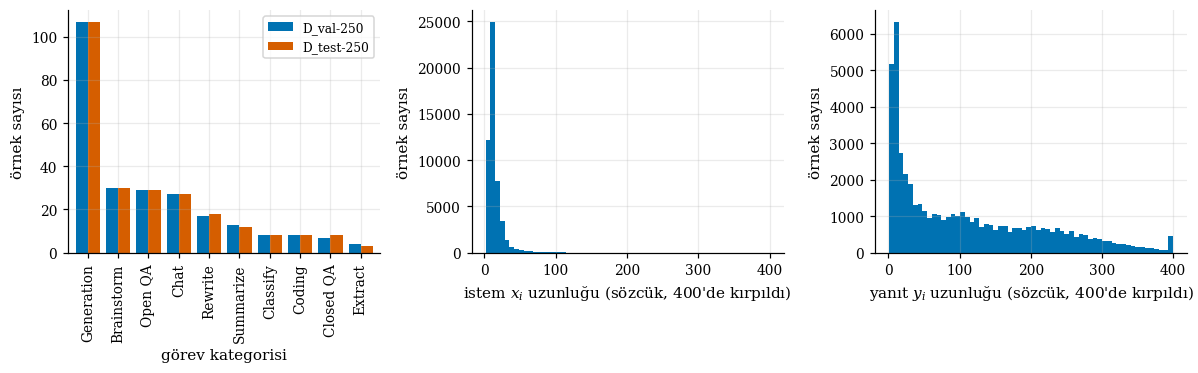

**Şekil 1.** (a) no_robots tabakalı bölünmesi; (b, c) alpaca-cleaned istem ve yanıt uzunluk dağılımları (sağa çarpık).

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
cat[["D_val-250", "D_test-250"]].plot.bar(ax=axes[0], width=0.8)
axes[0].set_xlabel("görev kategorisi"); axes[0].set_ylabel("örnek sayısı")
for ax, (col, lab) in zip(axes[1:], [("prompt", "istem $x_i$"), ("response", "yanıt $y_i$")]):
    w = pool_raw[col].str.split().str.len().clip(upper=400)
    ax.hist(w, bins=60, color="#0072B2")
    ax.set_xlabel(f"{lab} uzunluğu (sözcük, 400'de kırpıldı)"); ax.set_ylabel("örnek sayısı")
fig.tight_layout()
show_figure(fig, "fig_dataset_overview",
            "(a) no_robots tabakalı bölünmesi; (b, c) alpaca-cleaned istem ve yanıt uzunluk dağılımları (sağa çarpık).")

## 0.3 Gösterim (notasyon)

| Simge | Anlam |
|---|---|
| $x_i, y_i$ | $i$. örneğin istemi ve yanıtı; $\lvert\cdot\rvert$ simge (token) sayısı |
| $c(i)$, $\mu_{c(i)}$ | $i$. örneğin K-Means küme etiketi ve küme merkezi ($M=20$) |
| $\pi_{base}$ | Dondurulmuş taban model (Qwen2.5-0.5B-Base, öznitelik çıkarımı) |
| $\mathbf{f}_i=(L_x,L_y,PPL,IFD,H_y,D_{div})\in[0,1]^6$ | MinMax-normalize öznitelik vektörü |
| $T_j$, $S_i=T_j(\mathbf{f}_i)$ | $j$. GP bireyi (sembolik ağaç) ve $i$. örneğin skoru |
| $f_{GP}^*$ | Evrim sonunda bulunan en iyi formül |
| $\mathcal{L}_{val}$ | $D_{val\text{-}250}$ üzerindeki çapraz entropi |
| $\pi_{ref}$ | Hizalama için başlangıç/referans politikası (kaynak SFT modeli) |
| $r_\phi$ | Dondurulmuş harici ödül modeli (GRM-Llama3-8B) |

## 0.4 Sonuç ve sonraki adım
Ortam ve veri bölünmeleri doğrulandı. Sıradaki defter: **01 – Anlamsal kümeleme ve öznitelik çıkarımı**.

> **Kayıtlı olması gereken bilgi (rapor için):** yukarıdaki Tablo 1 (ortam) ve Tablo 2–3 (veri) doğrudan "Yöntem / Deney Kurulumu" bölümüne aktarılabilir;
> tablolar `outputs/tables/*.csv|tex`, şekiller `outputs/figures/*.png|pdf` olarak otomatik kaydedilir.

In [7]:
# Colab VM'de outputs/ oturum kapanınca silinir: sonuçları yerel makineye indirin.
from common import export_outputs
export_outputs("outputs_00")

ImportError: cannot import name 'export_outputs' from 'common' (/content/gp-stratified-sft-selection/src/common.py)